In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sqlalchemy import create_engine

engine = create_engine("postgresql+psycopg2:///transporte")

viagens = pd.read_sql("""
    SELECT v.*, r.nome AS rota, r.regiao,
           v.tempo_real_min - r.tempo_previsto_min AS atraso
    FROM viagens v
    JOIN rotas r ON r.id = v.rota_id
""", engine)

viagens["data"] = pd.to_datetime(viagens["data"])
viagens["pontual"] = viagens["atraso"] <= 5
viagens.head()

,id,rota_id,veiculo_placa,data,turno,tempo_real_min,passageiros,rota,regiao,atraso,pontual
0,1,1,LAA9R90,2026-07-27,Manhã,66,25,Rota 01,Plano Piloto,5,True
1,2,1,LCX8P84,2026-07-27,Tarde,61,36,Rota 01,Plano Piloto,0,True
2,3,2,VOX4K48,2026-07-27,Manhã,74,35,Rota 02,Plano Piloto,7,False
3,4,2,LHG0E65,2026-07-27,Tarde,68,48,Rota 02,Plano Piloto,1,True
4,5,3,VRR3M29,2026-07-27,Manhã,64,34,Rota 03,Taguatinga,6,False


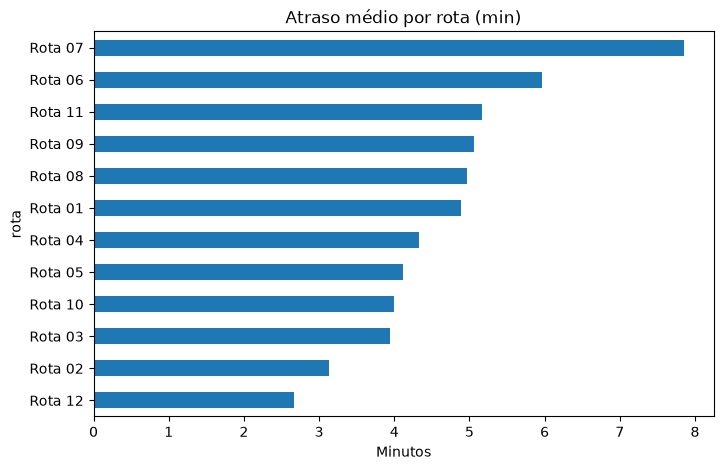

In [2]:
por_rota = viagens.groupby("rota")["atraso"].mean().sort_values()
por_rota.plot(kind="barh", figsize=(8, 5))
plt.title("Atraso médio por rota (min)")
plt.xlabel("Minutos")
plt.show()

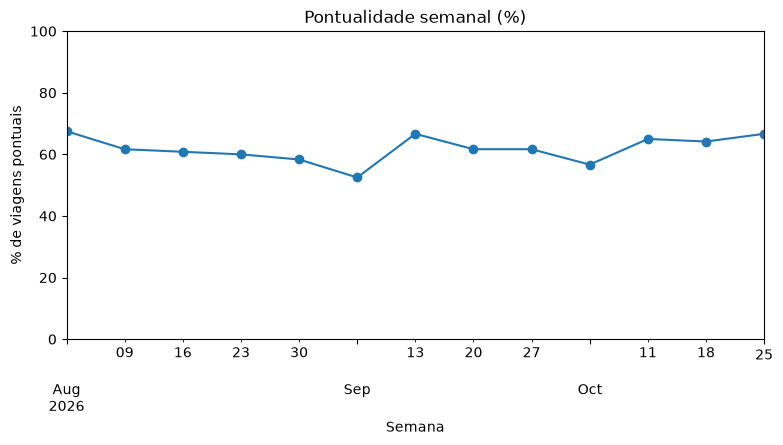

In [3]:
semanal = viagens.set_index("data").resample("W")["pontual"].mean() * 100
semanal.plot(figsize=(9, 4), marker="o")
plt.title("Pontualidade semanal (%)")
plt.xlabel("Semana")
plt.ylabel("% de viagens pontuais")
plt.ylim(0, 100)
plt.show()

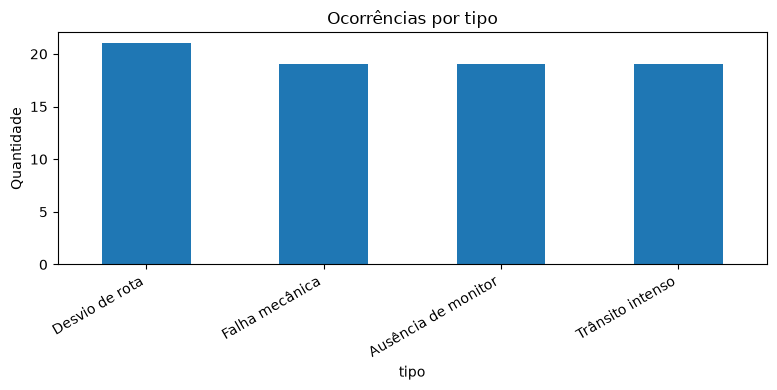

In [4]:
ocorrencias = pd.read_sql("SELECT * FROM ocorrencias", engine)
por_tipo = ocorrencias["tipo"].value_counts()
por_tipo.plot(kind="bar", figsize=(8, 4))
plt.title("Ocorrências por tipo")
plt.ylabel("Quantidade")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

In [5]:
print("Pontualidade geral:", round(viagens["pontual"].mean() * 100, 1), "%")
print()
print("Atraso médio por turno:")
print(viagens.groupby("turno")["atraso"].mean().round(1))
print()
print("Atraso médio por região:")
print(viagens.groupby("regiao")["atraso"].mean().round(1).sort_values(ascending=False))
print()
print("5 dias com maior atraso médio:")
print(viagens.groupby("data")["atraso"].mean().sort_values(ascending=False).head(5).round(1))
print("Média geral:", round(viagens["atraso"].mean(), 1), "min")

Pontualidade geral: 61.8 %

Atraso médio por turno:
turno
Manhã    4.0
Tarde    5.3
Name: atraso, dtype: float64

Atraso médio por região:
regiao
Samambaia       6.4
Ceilândia       5.0
Gama            4.5
Taguatinga      4.1
Plano Piloto    4.0
Sobradinho      3.9
Name: atraso, dtype: float64

5 dias com maior atraso médio:
data
2026-08-31    7.5
2026-09-04    7.1
2026-08-12    6.9
2026-10-01    6.9
2026-09-25    6.7
Name: atraso, dtype: float64
Média geral: 4.7 min


# Análise de operações de transporte escolar

Dados fictícios gerados para demonstração. Viagem pontual: atraso de até 5 minutos.

## Principais achados
- A rota com maior atraso médio é a ... (... min). A região com pior desempenho é ...
- A pontualidade geral é de ...%.
- As viagens da tarde atrasam ... min a mais que as da manhã.
- Em dias de chuva, o atraso médio chega a ... min, contra ... min na média geral.
- A ocorrência mais comum é ..., com ... casos.

## Recomendações
- ...
- ...